In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

!pip install datasets transformers accelerate bitsandbytes sentencepiece pandas matplotlib tqdm --quiet

In [ ]:
import os
import random
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, BitsAndBytesConfig

In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL_NAME_Q = "Qwen/Qwen2.5-7B-Instruct"
bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME_Q)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME_Q,
    quantization_config=bnb_config,
    device_map={"": 0},
)
print("Model parameter device:", next(model.parameters()).device)
print(f"GPU memory after load: {torch.cuda.memory_allocated()/1e9:.2f} GB")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Model parameter device: cuda:0
GPU memory after load: 5.85 GB


In [ ]:
def call_llm_causal(prompt: str) -> str:
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=5120).to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
        )
    generated_only = output_ids[0][inputs["input_ids"].shape[1]:]  # slice off the echoed prompt
    return tokenizer.decode(generated_only, skip_special_tokens=True).strip()

In [ ]:
CONFIG_Q = {
    "model": "qwen2.5-7b-instruct-4bit",
    "languages": {"English": "eng_Latn", "Sinhala": "sin_Sinh"},
    "shot_counts": [0, 1, 2, 4, 8],
    "n_exemplar_pool": 20,
    "n_test_samples": 20,
    "n_seeds": 2,
    "random_seed_base": 42,
    "output_dir": "/content/drive/MyDrive/belebele_results/results_qwen",
}
os.makedirs(CONFIG_Q["output_dir"], exist_ok=True)

In [ ]:
def load_and_split(lang_code: str, seed: int, config):
    ds = load_dataset("facebook/belebele", lang_code, split="test")
    ds = ds.shuffle(seed=seed)
    exemplar_pool = ds.select(range(config["n_exemplar_pool"]))
    remaining = ds.select(range(
        config["n_exemplar_pool"],
        config["n_exemplar_pool"] + config["n_test_samples"]
    ))
    return exemplar_pool, remaining

In [ ]:
LETTERS = ["A", "B", "C", "D"]

def format_question_block(row, show_answer: bool):
    options = [row["mc_answer1"], row["mc_answer2"], row["mc_answer3"], row["mc_answer4"]]
    block = f"Passage: {row['flores_passage']}\n"
    block += f"Question: {row['question']}\n"
    for letter, opt in zip(LETTERS, options):
        block += f"{letter}. {opt}\n"
    if show_answer:
        correct_letter = LETTERS[int(row["correct_answer_num"]) - 1]
        block += f"Answer: {correct_letter}\n"
    else:
        block += "Answer:"
    return block

def build_prompt(exemplars, target_row):
    parts = [format_question_block(ex, show_answer=True) for ex in exemplars]
    parts.append(format_question_block(target_row, show_answer=False))
    instructions = (
        "Answer each multiple-choice reading comprehension question "
        "using only the passage provided. Respond with a single "
        "letter (A, B, C, or D) and nothing else."
    )
    return instructions + "\n\n" + "\n\n".join(parts)

In [ ]:
def sample_exemplars(exemplar_pool, k, seed):
    rng = random.Random(seed)
    if k == 0:
        return []
    indices = rng.sample(range(len(exemplar_pool)), k)
    return [exemplar_pool[i] for i in indices]

In [ ]:
tokenizer.truncation_side = "left"

def build_prompt_chat(exemplars, target_row):
    parts = [format_question_block(ex, show_answer=True) for ex in exemplars]
    parts.append(format_question_block(target_row, show_answer=False))
    instructions = (
        "Answer each multiple-choice reading comprehension question "
        "using only the passage provided. Respond with a single "
        "letter (A, B, C, or D) and nothing else."
    )
    user_content = instructions + "\n\n" + "\n\n".join(parts)
    messages = [{"role": "user", "content": user_content}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

def call_llm_chat(prompt: str) -> str:
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=5120).to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=3,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )
    generated_only = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated_only, skip_special_tokens=True).strip()

def parse_prediction(raw_output: str):
    raw_output = raw_output.strip()
    if not raw_output:
        return None
    first_char = raw_output[0].upper()
    if first_char in LETTERS:
        return first_char
    return None

In [ ]:
print(parse_prediction("B   Passage:"))  # should print B

B


In [ ]:
exemplar_pool, test_pool = load_and_split(CONFIG_Q["languages"]["Sinhala"], seed=CONFIG_Q["random_seed_base"], config=CONFIG_Q)
exemplars_timing = sample_exemplars(exemplar_pool, 8, 42)
target = test_pool[0]
test_prompt = build_prompt_chat(exemplars_timing, target)

start = time.time()
_ = call_llm_chat(test_prompt)
elapsed = time.time() - start

total_calls = len(CONFIG_Q["languages"]) * len(CONFIG_Q["shot_counts"]) * CONFIG_Q["n_seeds"] * CONFIG_Q["n_test_samples"]
print(f"One 8-shot Qwen call took {elapsed:.2f} seconds")
print(f"Total calls planned: {total_calls}")
print(f"Estimated total run time: {elapsed * total_calls / 60:.1f} minutes")

One 8-shot Qwen call took 10.61 seconds
Total calls planned: 400
Estimated total run time: 70.7 minutes


In [ ]:
def run_experiment_q():
    all_results = []
    for lang_name, lang_code in CONFIG_Q["languages"].items():
        print(f"\n=== Language: {lang_name} ({lang_code}) ===")
        exemplar_pool, test_pool = load_and_split(lang_code, seed=CONFIG_Q["random_seed_base"], config=CONFIG_Q)

        for shot_count in CONFIG_Q["shot_counts"]:
            for seed_offset in range(CONFIG_Q["n_seeds"]):
                seed = CONFIG_Q["random_seed_base"] + seed_offset
                exemplars = sample_exemplars(exemplar_pool, shot_count, seed)

                correct, total = 0, 0
                letter_counts = {"A": 0, "B": 0, "C": 0, "D": 0, "None": 0}
                for row in tqdm(test_pool, desc=f"{lang_name} | shots={shot_count} | seed={seed}"):
                    prompt = build_prompt_chat(exemplars, row)
                    try:
                        raw = call_llm_chat(prompt)
                    except Exception as e:
                        print(f"Generation error: {type(e).__name__}: {e}")
                        torch.cuda.empty_cache()
                        continue

                    pred = parse_prediction(raw)
                    gold = LETTERS[int(row["correct_answer_num"]) - 1]
                    total += 1
                    if pred == gold:
                        correct += 1
                    letter_counts[pred if pred else "None"] += 1

                accuracy = correct / total if total > 0 else 0.0
                torch.cuda.empty_cache()
                all_results.append({
                    "language": lang_name, "shot_count": shot_count, "seed": seed,
                    "accuracy": accuracy, "n_scored": total, **letter_counts,
                })
                pd.DataFrame(all_results).to_csv(f"{CONFIG_Q['output_dir']}/qwen_raw_results.csv", index=False)

    return pd.DataFrame(all_results)


=== Language: English (eng_Latn) ===


English | shots=0 | seed=42: 100%|██████████| 20/20 [00:08<00:00,  2.46it/s]
English | shots=0 | seed=43: 100%|██████████| 20/20 [00:08<00:00,  2.38it/s]
English | shots=1 | seed=42: 100%|██████████| 20/20 [00:10<00:00,  1.90it/s]
English | shots=1 | seed=43: 100%|██████████| 20/20 [00:10<00:00,  1.97it/s]
English | shots=2 | seed=42: 100%|██████████| 20/20 [00:13<00:00,  1.49it/s]
English | shots=2 | seed=43: 100%|██████████| 20/20 [00:11<00:00,  1.68it/s]
English | shots=4 | seed=42: 100%|██████████| 20/20 [00:18<00:00,  1.07it/s]
English | shots=4 | seed=43: 100%|██████████| 20/20 [00:20<00:00,  1.03s/it]
English | shots=8 | seed=42: 100%|██████████| 20/20 [00:34<00:00,  1.71s/it]
English | shots=8 | seed=43: 100%|██████████| 20/20 [00:32<00:00,  1.63s/it]



=== Language: Sinhala (sin_Sinh) ===


Sinhala | shots=0 | seed=42: 100%|██████████| 20/20 [00:25<00:00,  1.27s/it]
Sinhala | shots=0 | seed=43: 100%|██████████| 20/20 [00:25<00:00,  1.28s/it]
Sinhala | shots=1 | seed=42: 100%|██████████| 20/20 [00:48<00:00,  2.41s/it]
Sinhala | shots=1 | seed=43: 100%|██████████| 20/20 [00:44<00:00,  2.21s/it]
Sinhala | shots=2 | seed=42: 100%|██████████| 20/20 [01:31<00:00,  4.57s/it]
Sinhala | shots=2 | seed=43: 100%|██████████| 20/20 [01:07<00:00,  3.37s/it]
Sinhala | shots=4 | seed=42: 100%|██████████| 20/20 [02:43<00:00,  8.19s/it]
Sinhala | shots=4 | seed=43: 100%|██████████| 20/20 [02:54<00:00,  8.74s/it]
Sinhala | shots=8 | seed=42: 100%|██████████| 20/20 [03:29<00:00, 10.47s/it]
Sinhala | shots=8 | seed=43: 100%|██████████| 20/20 [03:29<00:00, 10.47s/it]


  language  shot_count   mean       std
0  English           0  0.900  0.000000
1  English           1  0.850  0.000000
2  English           2  0.875  0.035355
3  English           4  0.850  0.000000
4  English           8  0.850  0.000000
5  Sinhala           0  0.650  0.000000
6  Sinhala           1  0.625  0.035355
7  Sinhala           2  0.600  0.000000
8  Sinhala           4  0.575  0.035355
9  Sinhala           8  0.450  0.070711


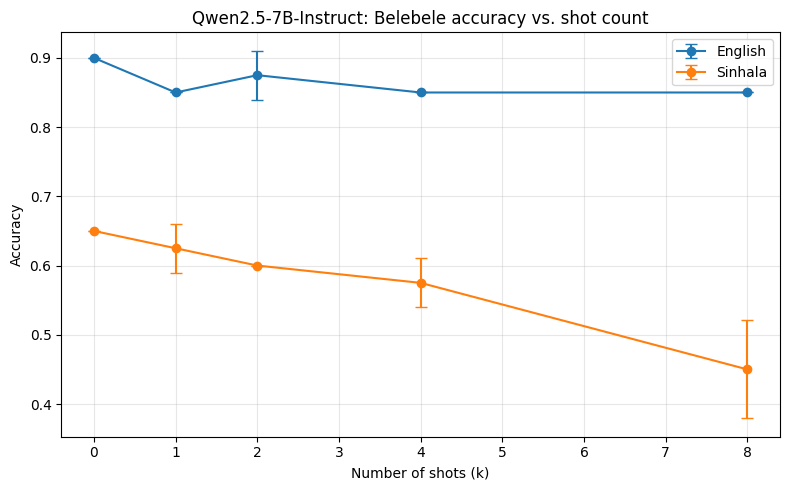

In [ ]:
qwen_df = run_experiment_q()
qwen_agg = qwen_df.groupby(["language", "shot_count"])["accuracy"].agg(["mean", "std"]).reset_index()
qwen_agg.to_csv(f"{CONFIG_Q['output_dir']}/qwen_aggregated.csv", index=False)
print(qwen_agg)

plt.figure(figsize=(8, 5))
for lang in qwen_agg["language"].unique():
    sub = qwen_agg[qwen_agg["language"] == lang].sort_values("shot_count")
    plt.errorbar(sub["shot_count"], sub["mean"], yerr=sub["std"].fillna(0), marker="o", capsize=4, label=lang)
plt.xlabel("Number of shots (k)")
plt.ylabel("Accuracy")
plt.title("Qwen2.5-7B-Instruct: Belebele accuracy vs. shot count")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CONFIG_Q['output_dir']}/qwen_shot_count_curve.png", dpi=300)
plt.show()

In [ ]:
exemplar_pool, test_pool = load_and_split(CONFIG_Q["languages"]["English"], seed=42, config=CONFIG_Q)
exemplars = sample_exemplars(exemplar_pool, 4, 42)
prompt = build_prompt(exemplars, test_pool[0])

raw = call_llm(prompt)
print(f"RAW OUTPUT: '{raw}'")
print(f"Prompt ending (last 300 chars): ...{prompt[-300:]}")

RAW OUTPUT: 'B


Passage:'
Prompt ending (last 300 chars): ...e stroke of midnight to celebrate Christ's resurrection.
Question: According to the passage, how is Easter celebrated by some especially traditional churches?
A. Holding a fertility ritual
B. Hosting a Saturday night vigil
C. Having a spring party for the congregation
D. Watching the sunrise
Answer:


In [ ]:
print(qwen_agg)

  language  shot_count   mean       std
0  English           0  0.900  0.000000
1  English           1  0.850  0.000000
2  English           2  0.875  0.035355
3  English           4  0.850  0.000000
4  English           8  0.850  0.000000
5  Sinhala           0  0.650  0.000000
6  Sinhala           1  0.625  0.035355
7  Sinhala           2  0.600  0.000000
8  Sinhala           4  0.575  0.035355
9  Sinhala           8  0.450  0.070711


In [ ]:
qwen_sinhala_k8 = qwen_df[(qwen_df["language"] == "Sinhala") & (qwen_df["shot_count"] == 8)]
print(qwen_sinhala_k8[["seed", "A", "B", "C", "D", "None"]])

    seed   A  B  C  D  None
18    42  10  3  5  1     1
19    43  10  4  4  2     0


In [ ]:
# Retry Sinhala k=16 on Qwen — smaller model may have enough memory headroom where mT0-XL didn't
exemplar_pool, test_pool_full = load_and_split(CONFIG_Q["languages"]["Sinhala"], seed=CONFIG_Q["random_seed_base"], config=CONFIG_Q)
test_pool = test_pool_full.select(range(20))

k16_qwen_results = []
for seed_offset in range(2):
    seed = CONFIG_Q["random_seed_base"] + seed_offset
    exemplars = sample_exemplars(exemplar_pool, 16, seed)

    correct, total = 0, 0
    for row in tqdm(test_pool, desc=f"Qwen | Sinhala | shots=16 | seed={seed}"):
        prompt = build_prompt_chat(exemplars, row)
        try:
            raw = call_llm_chat(prompt)
        except Exception as e:
            print(f"Error: {type(e).__name__}: {e}")
            torch.cuda.empty_cache()
            continue
        pred = parse_prediction(raw)
        gold = LETTERS[int(row["correct_answer_num"]) - 1]
        total += 1
        if pred == gold:
            correct += 1
    accuracy = correct / total if total > 0 else 0.0
    torch.cuda.empty_cache()
    k16_qwen_results.append({"seed": seed, "accuracy": accuracy, "n_scored": total})

print(pd.DataFrame(k16_qwen_results))

Qwen | Sinhala | shots=16 | seed=42: 100%|██████████| 20/20 [03:30<00:00, 10.50s/it]
Qwen | Sinhala | shots=16 | seed=43: 100%|██████████| 20/20 [03:29<00:00, 10.47s/it]


   seed  accuracy  n_scored
0    42       0.5        20
1    43       0.4        20


In [ ]:
exemplar_pool, test_pool_full = load_and_split(CONFIG_Q["languages"]["Sinhala"], seed=CONFIG_Q["random_seed_base"], config=CONFIG_Q)
test_pool = test_pool_full.select(range(20))

k16_qwen_letters = []
for seed_offset in range(2):
    seed = CONFIG_Q["random_seed_base"] + seed_offset
    exemplars = sample_exemplars(exemplar_pool, 16, seed)

    correct, total = 0, 0
    letter_counts = {"A": 0, "B": 0, "C": 0, "D": 0, "None": 0}
    for row in tqdm(test_pool, desc=f"Qwen | Sinhala | shots=16 | seed={seed}"):
        prompt = build_prompt_chat(exemplars, row)
        try:
            raw = call_llm_chat(prompt)
        except Exception as e:
            print(f"Error: {type(e).__name__}: {e}")
            torch.cuda.empty_cache()
            continue
        pred = parse_prediction(raw)
        gold = LETTERS[int(row["correct_answer_num"]) - 1]
        total += 1
        if pred == gold:
            correct += 1
        letter_counts[pred if pred else "None"] += 1

    accuracy = correct / total if total > 0 else 0.0
    torch.cuda.empty_cache()
    k16_qwen_letters.append({"seed": seed, "accuracy": accuracy, "n_scored": total, **letter_counts})

print(pd.DataFrame(k16_qwen_letters))

Qwen | Sinhala | shots=16 | seed=42: 100%|██████████| 20/20 [03:30<00:00, 10.52s/it]
Qwen | Sinhala | shots=16 | seed=43: 100%|██████████| 20/20 [03:29<00:00, 10.48s/it]


   seed  accuracy  n_scored  A  B  C  D  None
0    42       0.5        20  9  6  5  0     0
1    43       0.4        20  9  4  4  3     0
